# 22: Fingerprint map

The detectors of E8 to E11 work on CLIP features: each 224 x 224 tile becomes a list of 768 numbers. This notebook draws those features as a map, so that the "fingerprints" can be seen.

Every test image of E10 and E11 (the average of its tile features) becomes one dot. t-SNE places the dots in two dimensions so that images with similar features end up close together. Distances between far-apart groups and the size of a group on the map mean little in t-SNE; only who is near whom matters. The map is therefore backed by a number computed in the full 768 dimensions: for each image, the share of its 10 nearest neighbours that belong to the same group (**neighbour agreement**).

Two maps are drawn, each as distributed and after the simulated WhatsApp share:

1. real photographs against generated images;
2. the generator families of E11, one family highlighted per panel.

Nothing is trained or downloaded; the notebook reuses the features saved by notebooks 19 and 20. A CPU runtime is enough (about 5 minutes).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

ROOT = Path("/content/drive/MyDrive/minor-project")
RESULTS = ROOT / "results"
DEPLOY = ROOT / "processed_deploy"

Mounted at /content/drive


## Settings

In [2]:
FAMILIES = [  # same grouping as E11 (notebook 21)
    ("ChatGPT", r"gpt|dall"),
    ("Gemini", r"nano|banana|imagen|gemini"),
    ("Grok", r"aurora|grok"),
    ("Midjourney", r"midjourney"),
    ("Flux", r"flux"),
]
SHOWN = ["ChatGPT", "Gemini", "Grok", "Midjourney", "Flux", "Other AI"]  # Seedream, Ideogram and Recraft count as Other AI here
MAX_PER_GROUP = 300         # images per family on the map
MAX_REAL = 600
NEIGHBOURS = 10
SEED = 42
REAL, AI, OTHER = "#2a78d6", "#eb6834", "#c9ccd1"   # same colours as the website


def family(source, y):
    if y == 0:
        return "Real"
    name = str(source).lower()
    return next((f for f, pattern in FAMILIES if re.search(pattern, name)), "Other AI")

## Image features

The tile features of each test image are averaged and normalised. The same images are used in both versions (as distributed and shared), so the two maps can be compared.

In [3]:
def e10(name):
    return np.load(DEPLOY / f"e10_{name}.npy"), pd.read_csv(DEPLOY / f"e10_{name}.csv", keep_default_na=False)


parts = [e10(f"openfake_test_{i:02d}") for i in [0, 1, 2]]
for name in ["commons_android", "commons_iphone", "unsplash_phone", "unsplash_camera", "gpt4o", "nano_banana"]:
    x, meta = e10(name)
    test = (meta["split"] == "test").to_numpy()
    parts.append((x[test], meta[test].reset_index(drop=True)))

features, rows = [], []
for x, meta in parts:
    meta = meta.assign(image=meta["source"].astype(str) + "/" + meta["image"].astype(str))
    for (image, version), index in meta.groupby(["image", "version"], sort=False).indices.items():
        f = x[index].astype(np.float32).mean(axis=0)
        features.append(f / np.linalg.norm(f))
        first = meta.iloc[index[0]]
        rows.append({"image": image, "version": version, "source": first["source"], "y": int(first["y"]),
                     "group": family(first["source"], int(first["y"]))})
features = np.stack(features)
images = pd.DataFrame(rows)
del parts

rng = np.random.default_rng(SEED)
chosen = []
for group, part in images[images["version"] == "original"].groupby("group"):
    names = part["image"].unique()
    limit = MAX_REAL if group == "Real" else MAX_PER_GROUP
    chosen.extend(rng.choice(names, size=min(limit, len(names)), replace=False))
keep = images["image"].isin(set(chosen)).to_numpy()
features, images = features[keep], images[keep].reset_index(drop=True)
print(images[images["version"] == "original"]["group"].value_counts().reindex(["Real"] + SHOWN).fillna(0).astype(int).to_string())

group
Real          634
ChatGPT       303
Gemini        301
Grok           71
Midjourney     90
Flux           90
Other AI      314


## Neighbour agreement

For each image, the share of its 10 nearest neighbours (cosine distance on the full 768 numbers) in the same group, averaged per group. Real against AI: chance would be the share of that class among the images. Families: only generated images are counted, so chance is the share of that family among them.

In [4]:
def agreement(x, labels):
    nn = NearestNeighbors(n_neighbors=NEIGHBOURS + 1, metric="cosine").fit(x)
    _, index = nn.kneighbors(x)
    same = (labels[index[:, 1:]] == labels[:, None]).mean(axis=1)
    return pd.Series(same).groupby(labels).mean()


table = []
for version in ["original", "shared"]:
    v = (images["version"] == version).to_numpy()
    kind = np.where(images["y"][v] == 1, "AI", "Real")
    for group, value in agreement(features[v], kind).items():
        table.append({"map": "real vs AI", "group": group, "version": version, "agreement": value,
                      "chance": (kind == group).mean()})
    a = v & (images["y"] == 1).to_numpy()
    fam = images["group"][a].to_numpy()
    for group, value in agreement(features[a], fam).items():
        table.append({"map": "families", "group": group, "version": version, "agreement": value,
                      "chance": (fam == group).mean()})
table = pd.DataFrame(table)
summary = table.pivot_table(index=["map", "group", "chance"], columns="version", values="agreement").reset_index()
summary.to_csv(RESULTS / "e12_neighbour_agreement.csv", index=False)
display(summary.round(3))

version,map,group,chance,original,shared
0,families,ChatGPT,0.259,0.669,0.632
1,families,Flux,0.077,0.438,0.326
2,families,Gemini,0.257,0.780,0.686
3,families,Grok,0.061,0.714,0.697
4,families,Midjourney,0.077,0.452,0.369
5,families,Other AI,0.269,0.475,0.443
6,real vs AI,AI,0.648,0.937,0.854
7,real vs AI,Real,0.352,0.960,0.890


## The maps

t-SNE is run separately for each version, first reducing the features to 50 dimensions with PCA (the usual setting). The coordinates are saved to Drive.

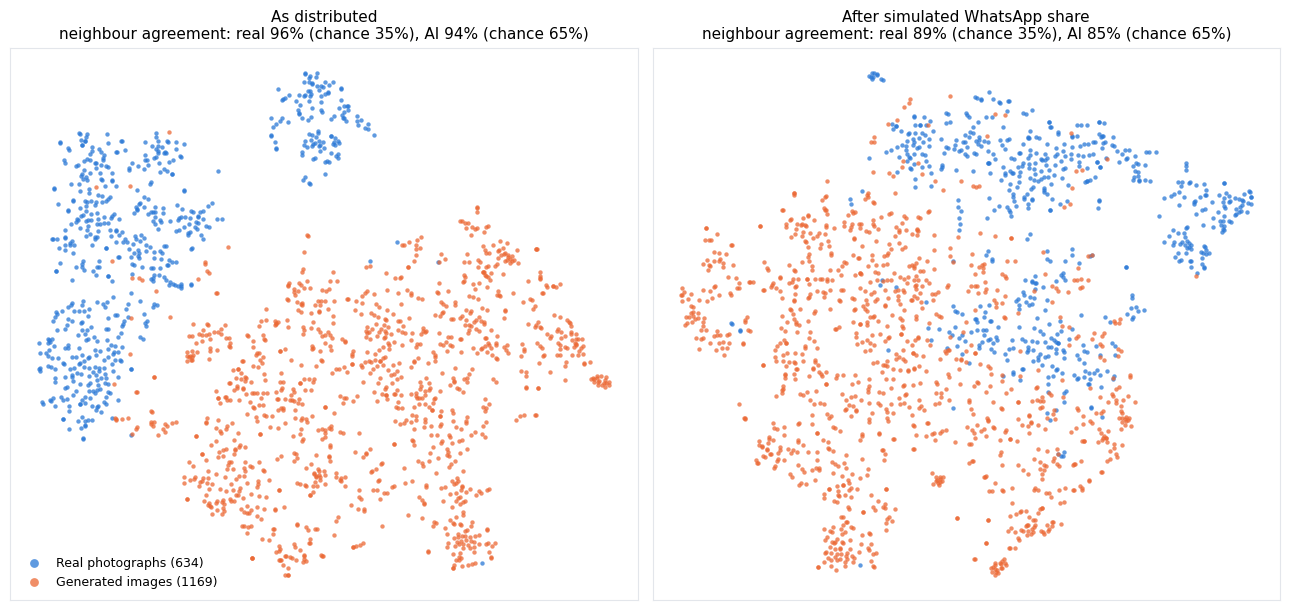

In [5]:
coords = np.zeros((len(images), 2))
for version in ["original", "shared"]:
    v = (images["version"] == version).to_numpy()
    reduced = PCA(n_components=min(50, v.sum() - 1), random_state=SEED).fit_transform(features[v])
    coords[v] = TSNE(n_components=2, perplexity=min(30, (v.sum() - 1) / 3), init="pca", random_state=SEED).fit_transform(reduced)
images[["x", "y_map"]] = coords
images.to_csv(RESULTS / "e12_map_coordinates.csv", index=False)

TITLES = {"original": "As distributed", "shared": "After simulated WhatsApp share"}


def clean(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#e3e6eb")


fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, version in zip(axes, ["original", "shared"]):
    part = images[images["version"] == version]
    for label, colour, mask in [("Real photographs", REAL, part["y"] == 0), ("Generated images", AI, part["y"] == 1)]:
        ax.scatter(part["x"][mask], part["y_map"][mask], s=10, c=colour, alpha=0.75, linewidths=0, label=f"{label} ({mask.sum()})")
    real_ai = summary[(summary["map"] == "real vs AI")].set_index("group")
    ax.set_title(f"{TITLES[version]}\nneighbour agreement: real {real_ai[version].get('Real', np.nan):.0%} (chance {real_ai['chance'].get('Real', np.nan):.0%}), "
                 f"AI {real_ai[version].get('AI', np.nan):.0%} (chance {real_ai['chance'].get('AI', np.nan):.0%})", fontsize=11)
    clean(ax)
axes[0].legend(loc="lower left", fontsize=9, frameon=False, markerscale=2)
plt.tight_layout()
plt.savefig(RESULTS / "e12_fingerprint_map.png", dpi=150)
plt.show()

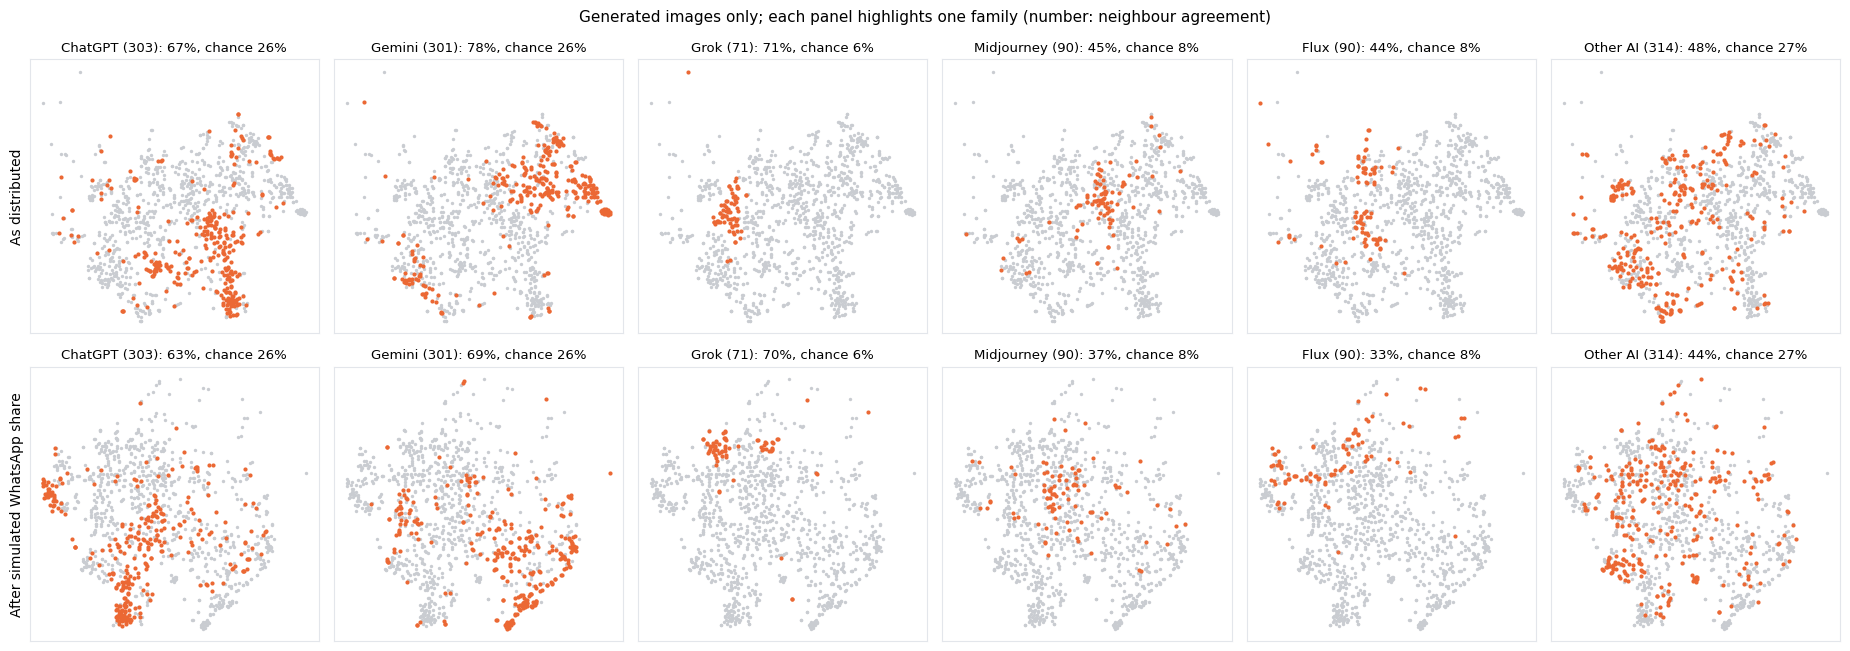

In [6]:
present = [f for f in SHOWN if (images["group"] == f).any()]
fig, axes = plt.subplots(2, len(present), figsize=(3.1 * len(present), 6.6), squeeze=False)
for row, version in enumerate(["original", "shared"]):
    part = images[(images["version"] == version) & (images["y"] == 1)]
    fam = summary[(summary["map"] == "families")].set_index("group")
    for ax, f in zip(axes[row], present):
        mine = part["group"] == f
        ax.scatter(part["x"][~mine], part["y_map"][~mine], s=6, c=OTHER, linewidths=0)
        ax.scatter(part["x"][mine], part["y_map"][mine], s=9, c=AI, linewidths=0)
        ax.set_title(f"{f} ({mine.sum()}): {fam[version].get(f, np.nan):.0%}, chance {fam['chance'].get(f, np.nan):.0%}", fontsize=9.5)
        clean(ax)
    axes[row][0].set_ylabel(TITLES[version], fontsize=10)
fig.suptitle("Generated images only; each panel highlights one family (number: neighbour agreement)", fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS / "e12_family_map.png", dpi=150)
plt.show()